<a href="https://colab.research.google.com/github/allnlk/ML/blob/main/%D0%9B%D0%91_13_%D0%9A%D1%83%D0%B1%D1%80%D0%B0%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from sklearn.metrics import classification_report

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import kagglehub

path = kagglehub.dataset_download('gpiosenka/cards-image-datasetclassification')
print('Шлях до даних:', path)
print(os.listdir(path))

100%|██████████| 385M/385M [00:22<00:00, 17.7MB/s]

Extracting files...


Шлях до даних: /root/.cache/kagglehub/datasets/gpiosenka/cards-image-datasetclassification/versions/2
['test', 'valid', '14card types-14-(200 X 200)-94.61.h5', 'train', 'cards.csv', '53cards-53-(200 X 200)-100.00.h5']


In [4]:
train_dir = os.path.join(path, 'train')
valid_dir = os.path.join(path, 'valid')
test_dir = os.path.join(path, 'test')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=True, seed=42)
val_ds = keras.utils.image_dataset_from_directory(
    valid_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print('Кількість класів:', num_classes)
print(class_names)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Кількість класів: 53
['ace of clubs', 'ace of diamonds', 'ace of hearts', 'ace of spades', 'eight of clubs', 'eight of diamonds', 'eight of hearts', 'eight of spades', 'five of clubs', 'five of diamonds', 'five of hearts', 'five of spades', 'four of clubs', 'four of diamonds', 'four of hearts', 'four of spades', 'jack of clubs', 'jack of diamonds', 'jack of hearts', 'jack of spades', 'joker', 'king of clubs', 'king of diamonds', 'king of hearts', 'king of spades', 'nine of clubs', 'nine of diamonds', 'nine of hearts', 'nine of spades', 'queen of clubs', 'queen of diamonds', 'queen of hearts', 'queen of spades', 'seven of clubs', 'seven of diamonds', 'seven of hearts', 'seven of spades', 'six of clubs', 'six of diamonds', 'six of hearts', 'six of spades', 'ten of clubs', 'ten of diamonds', 'ten of hearts', 'ten of spades', 'three of clubs', 'three of diamonds', 'th

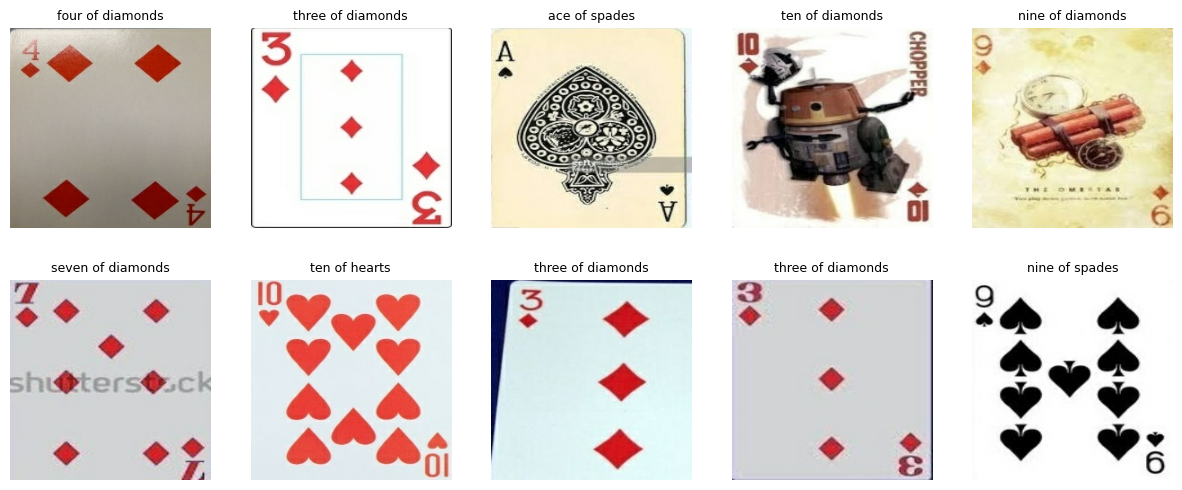

In [5]:
plt.figure(figsize=(15, 6))
for images, labels in train_ds.take(1):
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.show()

Навчальна вибірка: 7624
Валідаційна вибірка: 265
Тестова вибірка: 265
Мінімум зображень у класі: 108
Максимум зображень у класі: 181


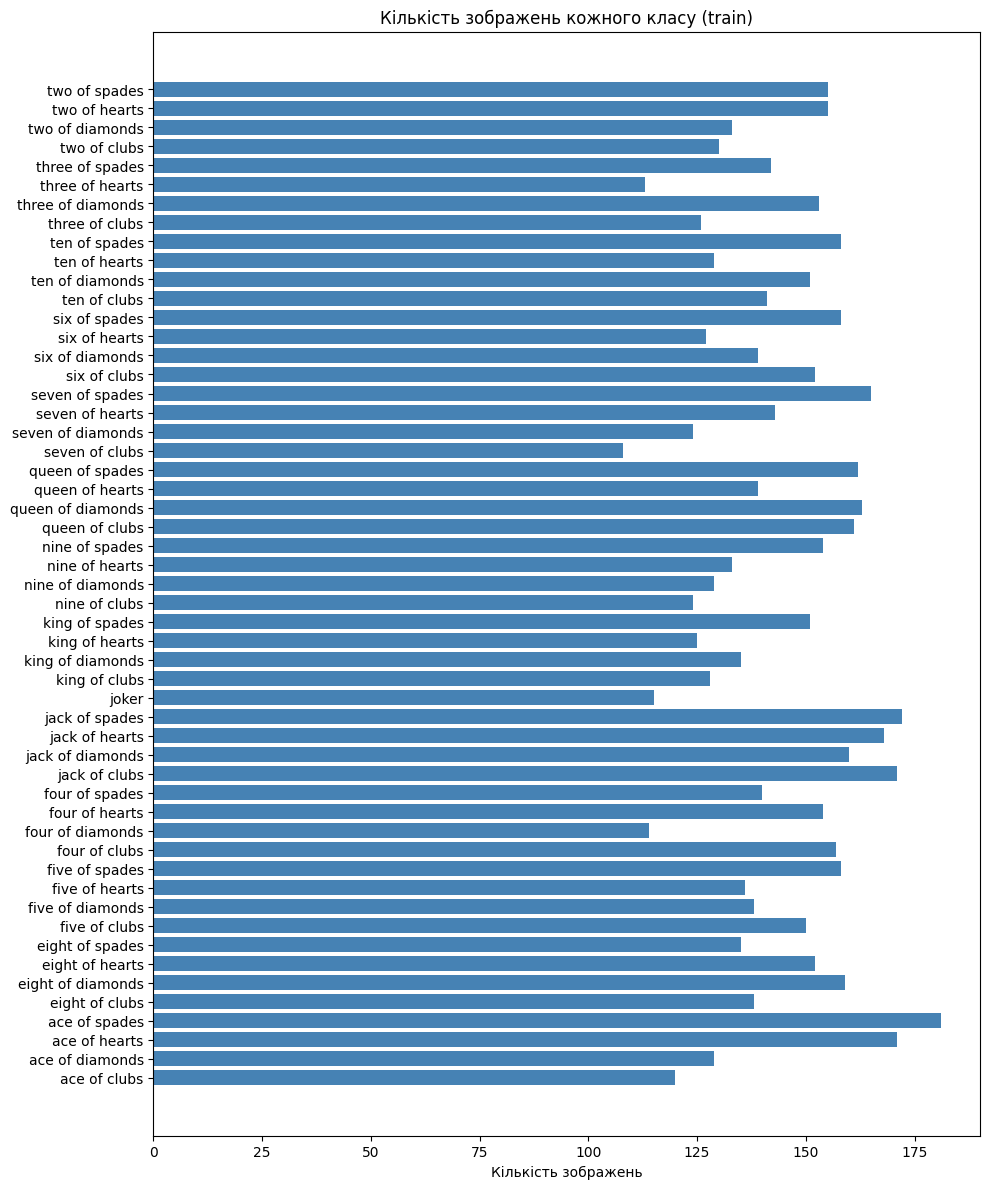

In [6]:
def count_images(folder):
    return sum(len(os.listdir(os.path.join(folder, c))) for c in os.listdir(folder))

print('Навчальна вибірка:', count_images(train_dir))
print('Валідаційна вибірка:', count_images(valid_dir))
print('Тестова вибірка:', count_images(test_dir))

class_counts = [len(os.listdir(os.path.join(train_dir, c))) for c in class_names]
print('Мінімум зображень у класі:', min(class_counts))
print('Максимум зображень у класі:', max(class_counts))

plt.figure(figsize=(10, 12))
plt.barh(class_names, class_counts, color='steelblue')
plt.title('Кількість зображень кожного класу (train)')
plt.xlabel('Кількість зображень')
plt.tight_layout()
plt.show()

In [7]:
for images, labels in train_ds.take(1):
    print('Розмір батчу зображень:', images.shape)
    print('Мінімальне значення пікселя:', images.numpy().min())
    print('Максимальне значення пікселя:', images.numpy().max())

Розмір батчу зображень: (32, 224, 224, 3)
Мінімальне значення пікселя: 0.0
Максимальне значення пікселя: 255.0


Висновок з аналізу: навчальна вибірка містить 7624 зображення, валідаційна — 265, тестова — 265 (загалом 8154 зображення по 53 класах). Класи у навчальній вибірці є відносно збалансованими (від 108 до 181 зображення на клас, у валідаційній та тестовій — по 5 зображень на клас). Усі зображення мають розмір 224 × 224 пікселі з 3 колірними каналами (RGB), а значення пікселів лежать у ненормалізованому діапазоні від 0.0 до 255.0.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

In [9]:
def build_cnn(filters=32, dense_units=128, dropout=0.3, learning_rate=1e-3):
    model = models.Sequential([
        keras.Input(shape=(224, 224, 3)),
        data_augmentation,
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(filters, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(filters * 2, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(filters * 4, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(filters * 4, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(dense_units, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 53)             │         6,837 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,607,093 (9.95 MB)

 Trainable params: 2,607,093 (9.95 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
!pip install keras-tuner -q

In [11]:
from keras_tuner.tuners import RandomSearch

def build_model(hp):
    return build_cnn(
        filters=hp.Choice('filters', [16, 32]),
        dense_units=hp.Int('dense_units', min_value=64, max_value=256, step=64),
        dropout=hp.Choice('dropout', [0.3, 0.5]),
        learning_rate=hp.Choice('learning_rate', [1e-3, 1e-4])
    )

tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_logs',
    project_name='cards_cnn'
)

tuner.search(train_ds, validation_data=val_ds, epochs=5)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print('Найкращі гіперпараметри:', best_hp.values)

Trial 3 Complete [00h 01m 24s]
val_accuracy: 0.4830188751220703

Best val_accuracy So Far: 0.7660377621650696
Total elapsed time: 00h 03m 46s
Найкращі гіперпараметри: {'filters': 16, 'dense_units': 256, 'dropout': 0.3, 'learning_rate': 0.001}


In [12]:
cnn_model = tuner.hypermodel.build(best_hp)

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 17s 61ms/step - accuracy: 0.2066 - loss: 3.0898 - val_accuracy: 0.4038 - val_loss: 1.7854
Epoch 2/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.4158 - loss: 2.1082 - val_accuracy: 0.6226 - val_loss: 1.3241
Epoch 3/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.5231 - loss: 1.7280 - val_accuracy: 0.6981 - val_loss: 1.0888
Epoch 4/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.5958 - loss: 1.4797 - val_accuracy: 0.7321 - val_loss: 0.9430
Epoch 5/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.6514 - loss: 1.2915 - val_accuracy: 0.7774 - val_loss: 0.7630
Epoch 6/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - accuracy: 0.6796 - loss: 1.1570 - val_accuracy: 0.8000 - val_loss: 0.7424
Epoch 7/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.6982 - loss: 1.0744 - val_accuracy: 0.8415 - val_loss: 0.6413
Epoch 8/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.7244 - loss: 0.9542 - 

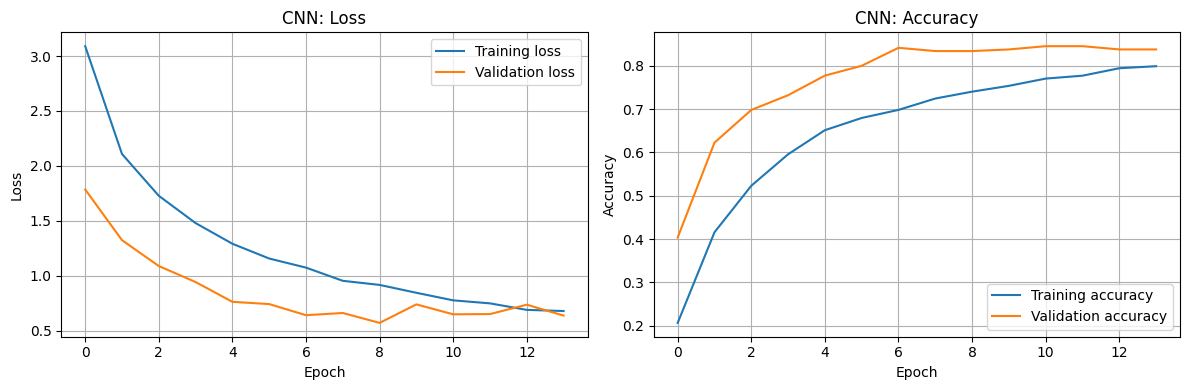

In [13]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['loss'], label='Training loss')
    plt.plot(history['val_loss'], label='Validation loss')
    plt.title(title + ': Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history['accuracy'], label='Training accuracy')
    plt.plot(history['val_accuracy'], label='Validation accuracy')
    plt.title(title + ': Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_history(cnn_history.history, 'CNN')

In [14]:
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds)
print('CNN test accuracy:', cnn_test_acc)
print('CNN test loss:', cnn_test_loss)

y_true = np.concatenate([y.numpy() for x, y in test_ds])
cnn_pred = np.argmax(cnn_model.predict(test_ds), axis=1)

print(classification_report(y_true, cnn_pred, target_names=class_names))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8302 - loss: 0.7042
CNN test accuracy: 0.8301886916160583
CNN test loss: 0.7042477130889893
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
                   precision    recall  f1-score   support

     ace of clubs       0.83      1.00      0.91         5
  ace of diamonds       1.00      1.00      1.00         5
    ace of hearts       1.00      1.00      1.00         5
    ace of spades       1.00      1.00      1.00         5
   eight of clubs       0.56      1.00      0.71         5
eight of diamonds       1.00      0.80      0.89         5
  eight of hearts       1.00      0.80      0.89         5
  eight of spades       0.67      0.80      0.73         5
    five of clubs       1.00      0.60      0.75         5
 five of diamonds       1.00      0.60      0.75         5
   five of hearts       1.00      1.00      1.00         5
   five of spades       1.00      0.80      0.89         5
    four of clubs       1.00      0.60      0.75  

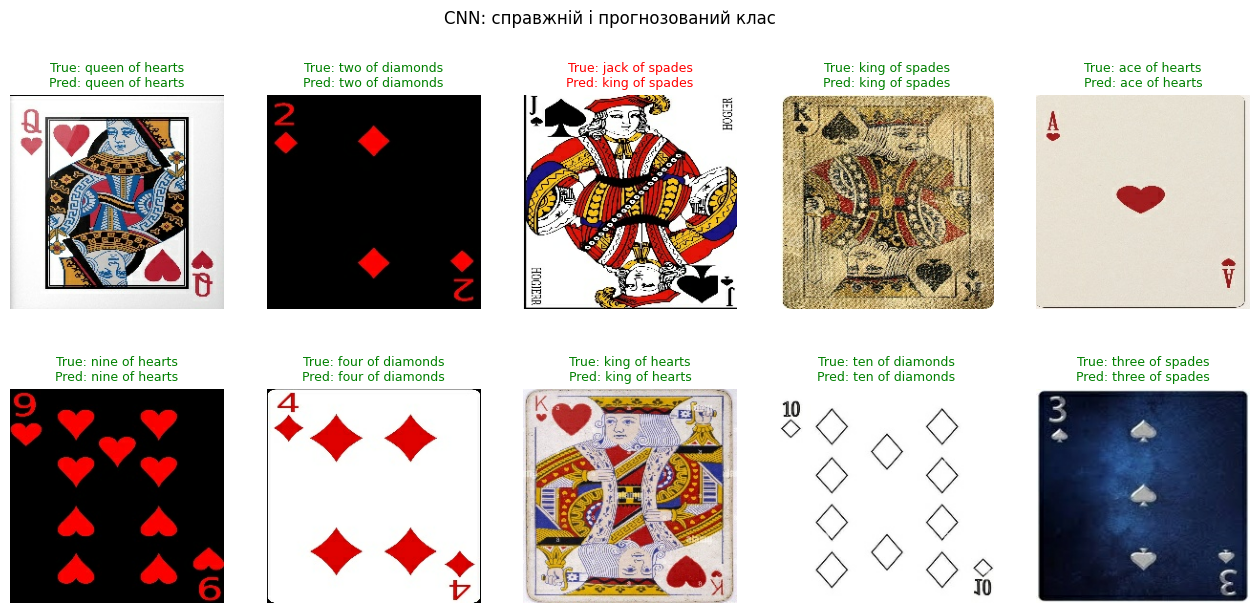

In [15]:
test_images = np.concatenate([x.numpy() for x, y in test_ds])

def show_predictions(predictions, title):
    idx = np.random.choice(len(test_images), 10, replace=False)
    plt.figure(figsize=(16, 7))
    for n, i in enumerate(idx):
        plt.subplot(2, 5, n + 1)
        plt.imshow(test_images[i].astype('uint8'))
        color = 'green' if predictions[i] == y_true[i] else 'red'
        plt.title(f'True: {class_names[y_true[i]]}\nPred: {class_names[predictions[i]]}',
                  color=color, fontsize=9)
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

show_predictions(cnn_pred, 'CNN: справжній і прогнозований клас')

**Проміжний висновок до завдання 1:** На тестовій вибірці модель CNN досягла точності 0.8302 (83.02%) при втратах 0.7042. Рання зупинка (EarlyStopping з patience=5 за val_loss) спрацювала на 14-й епосі (найкращі ваги відновлено з 9-ї епохи, де val_loss був мінімальним — 0.5713). Найкращими гіперпараметрами за результатами пошуку RandomSearch виявилися: filters = 16, dense_units = 256, dropout = 0.3 та learning_rate = 0.001.

In [16]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

vgg_model = keras.Model(inputs, outputs)

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[6][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[6][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[6][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 256)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 53)        │     13,621 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,859,637 (56.69 MB)

 Trainable params: 144,949 (566.21 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [17]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

vgg_history1 = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 50s 174ms/step - accuracy: 0.0913 - loss: 4.0485 - val_accuracy: 0.2377 - val_loss: 2.6242
Epoch 2/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 35s 148ms/step - accuracy: 0.1992 - loss: 2.8566 - val_accuracy: 0.2981 - val_loss: 2.1405
Epoch 3/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 36s 152ms/step - accuracy: 0.2702 - loss: 2.5011 - val_accuracy: 0.3925 - val_loss: 1.8793
Epoch 4/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 36s 151ms/step - accuracy: 0.3072 - loss: 2.2921 - val_accuracy: 0.3774 - val_loss: 1.9046
Epoch 5/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 36s 149ms/step - accuracy: 0.3528 - loss: 2.1325 - val_accuracy: 0.4302 - val_loss: 1.7761
Epoch 6/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 36s 151ms/step - accuracy: 0.3851 - loss: 2.0141 - val_accuracy: 0.4642 - val_loss: 1.6032
Epoch 7/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 35s 148ms/step - accuracy: 0.4062 - loss: 1.9399 - val_accuracy: 0.4566 - val_loss: 1.6813
Epoch 8/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 36s 149ms/step - accuracy: 0.4204 - loss: 1

In [18]:
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith('block5')

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

vgg_history2 = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 45s 177ms/step - accuracy: 0.4492 - loss: 1.7885 - val_accuracy: 0.5358 - val_loss: 1.3529
Epoch 2/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 42s 177ms/step - accuracy: 0.4869 - loss: 1.6504 - val_accuracy: 0.6000 - val_loss: 1.2454
Epoch 3/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 43s 179ms/step - accuracy: 0.5248 - loss: 1.5248 - val_accuracy: 0.6415 - val_loss: 1.1521
Epoch 4/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 81s 175ms/step - accuracy: 0.5291 - loss: 1.4871 - val_accuracy: 0.6604 - val_loss: 1.0097
Epoch 5/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 171ms/step - accuracy: 0.5586 - loss: 1.3977 - val_accuracy: 0.6528 - val_loss: 1.0085
Epoch 6/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 42s 177ms/step - accuracy: 0.5837 - loss: 1.3195 - val_accuracy: 0.6604 - val_loss: 0.9845
Epoch 7/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 80s 169ms/step - accuracy: 0.6009 - loss: 1.2535 - val_accuracy: 0.7132 - val_loss: 0.9173
Epoch 8/15
239/239 ━━━━━━━━━━━━━━━━━━━━ 41s 171ms/step - accuracy: 0.6124 - loss: 1

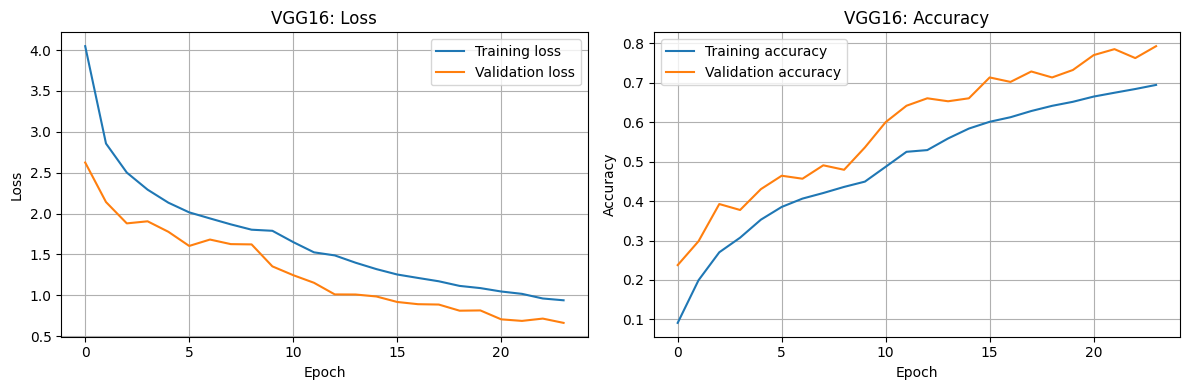

Епох на першому етапі: 9
Епох на етапі донавчання: 15


In [19]:
vgg_history = {}
for key in ['loss', 'val_loss', 'accuracy', 'val_accuracy']:
    vgg_history[key] = vgg_history1.history[key] + vgg_history2.history[key]

plot_history(vgg_history, 'VGG16')
print('Епох на першому етапі:', len(vgg_history1.history['loss']))
print('Епох на етапі донавчання:', len(vgg_history2.history['loss']))

In [20]:
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_ds)
print('VGG16 test accuracy:', vgg_test_acc)
print('VGG16 test loss:', vgg_test_loss)

vgg_pred = np.argmax(vgg_model.predict(test_ds), axis=1)
print(classification_report(y_true, vgg_pred, target_names=class_names))

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.7057 - loss: 0.9462
VGG16 test accuracy: 0.7056604027748108
VGG16 test loss: 0.9461507797241211
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step
                   precision    recall  f1-score   support

     ace of clubs       1.00      1.00      1.00         5
  ace of diamonds       1.00      1.00      1.00         5
    ace of hearts       0.50      1.00      0.67         5
    ace of spades       0.83      1.00      0.91         5
   eight of clubs       0.44      0.80      0.57         5
eight of diamonds       0.57      0.80      0.67         5
  eight of hearts       0.80      0.80      0.80         5
  eight of spades       0.33      0.20      0.25         5
    five of clubs       1.00      0.60      0.75         5
 five of diamonds       0.60      0.60      0.60         5
   five of hearts       1.00      0.60      0.75         5
   five of spades       0.50      1.00      0.67         5
    four of clubs       1.00      1.00      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


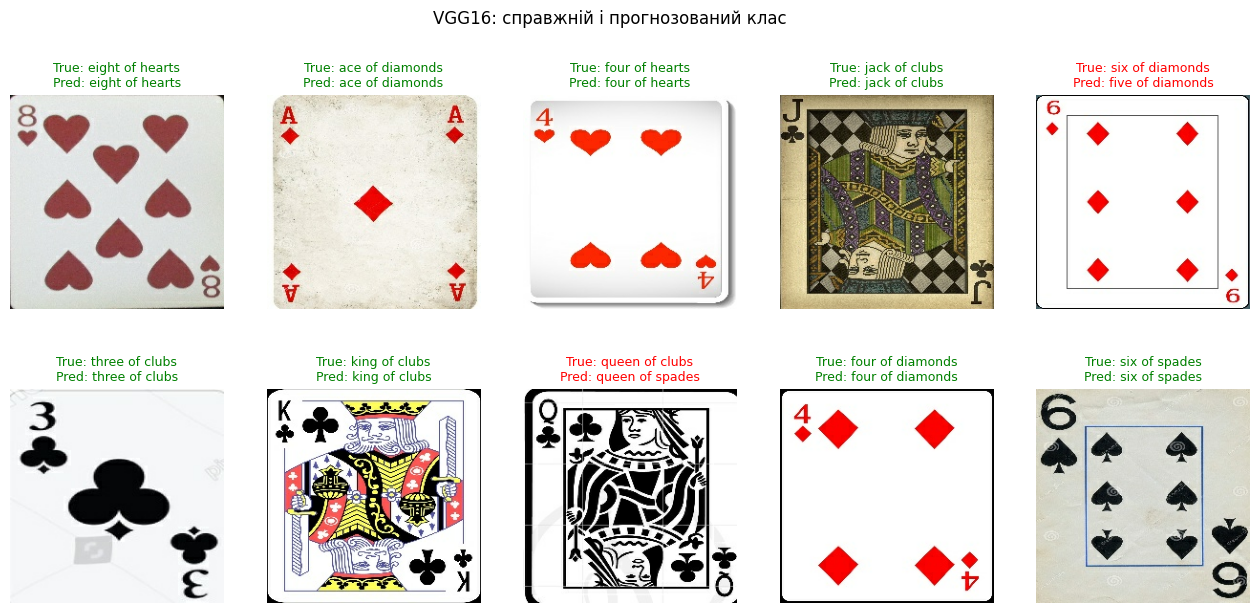

In [21]:
show_predictions(vgg_pred, 'VGG16: справжній і прогнозований клас')


## Висновки. Порівняння моделей

| Показник | Згорткова модель (CNN) | VGG16 (донавчена) |
| :--- | :--- | :--- |
| Точність на тестовій вибірці (accuracy) | **0.8302 (83.02%)** | **0.7057 (70.57%)** |
| Втрати на тестовій вибірці (loss) | **0.7042** | **0.9462** |
| Кількість епох навчання | **14** (найкращі ваги — 9-та епоха) | **24** (9 — базовий етап, 15 — fine-tuning) |
| Найкращі гіперпараметри | `filters=16`, `dense_units=256`, `dropout=0.3`, `lr=0.001` | — |

*Висновки:* За результатами тестування власна згорткова нейронна мережа (**CNN**) показала значно кращий результат, досягнувши точності **83.02%** проти **70.57%** у донавченої моделі **VGG16** (при нижчих втратах: 0.7042 проти 0.9462). Власна CNN швидше зійшлася до оптимуму (9–14 епох), оскільки її архітектура з нуля адаптувалася під специфічні ознаки гральних карт (номінали, масті, кутові символи). Натомість попередньо навчена на загальних об'єктах ImageNet модель VGG16 зіткнулася з недонавчанням на першому етапі (9 епох) і навіть після розморожування 5-го блоку (`block5`) на 15 епохах не змогла перевершити спеціалізовану CNN через обмежену кількість епох fine-tuning та малий крок навчання (`1e-5`)